# Deep Learning, Phase 2 (CNNs), Day 3: Project, Fashion-MNIST Classifier with Batch Norm and Dropout
Today is the main project of Phase 2. Steps:
1. Setup and data (same as Day 2)  2. Batch normalization and dropout  3. The improved CNN  4. Training and comparison with Day 2's CNN  5. **Final test evaluation (once)**  6. Confusion matrix and per-class results  7. Misclassified images  8. What did the CNN learn? Filters and feature maps  9. Save

In [ ]:
import copy, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
sns.set_theme(style='whitegrid')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)
if device == 'cpu': print('WARNING: no GPU found, training will be slow.')
torch.manual_seed(0); np.random.seed(0)

tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_full = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=tf)       # locked until section 5
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(0))
classes = train_full.classes
train_dl = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
val_dl = DataLoader(val_set, batch_size=512, num_workers=2)
test_dl = DataLoader(test_set, batch_size=512, num_workers=2)
print('Train:', len(train_set), '| Validation:', len(val_set), '| Test (locked):', len(test_set))

Using device: cpu


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.2MB/s]

Train: 55000 | Validation: 5000 | Test (locked): 10000


## 1. Training helpers
New today: the function keeps the weights of the **best epoch** (lowest validation loss) and restores them at the end, so we do not keep a model that has started to overfit. (Same idea as early stopping in Phase 1.)

In [ ]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, dl):
    model.eval(); tot = correct = n = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot / n, correct / n

def train(model, epochs=10, lr=1e-3):
    model.to(device); opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {'loss': [], 'val_loss': [], 'val_acc': [], 'time': []}; best, best_state, best_ep = float('inf'), None, 0
    for ep in range(epochs):
        t0 = time.time(); model.train(); run = n = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            run += loss.item() * len(yb); n += len(yb)
        vl, va = evaluate(model, val_dl)
        for k, v in zip(hist, (run / n, vl, va, time.time() - t0)): hist[k].append(v)
        if vl < best: best, best_state, best_ep = vl, copy.deepcopy(model.state_dict()), ep + 1
        print(f'epoch {ep + 1:2d}/{epochs}  train loss {run / n:.3f}  val loss {vl:.3f}  val acc {va:.3f}  ({time.time() - t0:.1f}s)')
    model.load_state_dict(best_state); hist['best_epoch'] = best_ep
    print('Restored the best epoch:', best_ep); return hist

n_params = lambda m: sum(p.numel() for p in m.parameters())
EPOCHS = 10

## 2. Batch normalization and dropout
**Batch normalization** (`nn.BatchNorm2d(channels)`): after a convolution, normalise each channel over the mini-batch (mean 0, std 1), then apply a learned scale and shift. Benefits: faster and more stable training, a higher learning rate is possible, and a small regularizing effect. It goes **between the convolution and the ReLU**. In `model.eval()` mode it uses running averages collected during training, so predictions do not depend on the other images in the batch.

**Dropout** (`nn.Dropout(p)`): randomly zeroes a fraction `p` of the values during training, so the network cannot depend on any single neuron (Phase 1, Day 5). We use it in the dense (classifier) part. It is switched off automatically by `model.eval()`.

## 3. Two models to compare
- **Day 2 CNN** (plain): 2 conv layers, no batch norm, no dropout.
- **Improved CNN**: 3 blocks of Conv -> BatchNorm -> ReLU -> MaxPool (16, 32, 64 filters), then Dropout and a dense layer. Sizes: 28 -> 14 -> 7 -> 3, so the flattened size is 64 x 3 x 3 = 576.

In [ ]:
def plain_cnn():
    torch.manual_seed(0)
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))

def improved_cnn(p_drop=0.3):
    torch.manual_seed(0)
    def block(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*block(1, 16), *block(16, 32), *block(32, 64),
                         nn.Flatten(), nn.Dropout(p_drop), nn.Linear(64 * 3 * 3, 128), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(128, 10))

x = torch.zeros(1, 1, 28, 28)
for layer in improved_cnn():
    x = layer(x); print(f'{layer.__class__.__name__:12s} -> {tuple(x.shape)}')
print('\nParameters  plain:', f'{n_params(plain_cnn()):,}', '| improved:', f'{n_params(improved_cnn()):,}')

Conv2d       -> (1, 16, 28, 28)
BatchNorm2d  -> (1, 16, 28, 28)
ReLU         -> (1, 16, 28, 28)
MaxPool2d    -> (1, 16, 14, 14)
Conv2d       -> (1, 32, 14, 14)
BatchNorm2d  -> (1, 32, 14, 14)
ReLU         -> (1, 32, 14, 14)
MaxPool2d    -> (1, 32, 7, 7)
Conv2d       -> (1, 64, 7, 7)
BatchNorm2d  -> (1, 64, 7, 7)
ReLU         -> (1, 64, 7, 7)
MaxPool2d    -> (1, 64, 3, 3)
Flatten      -> (1, 576)
Dropout      -> (1, 576)
Linear       -> (1, 128)
ReLU         -> (1, 128)
Dropout      -> (1, 128)
Linear       -> (1, 10)

Parameters  plain: 105,866 | improved: 98,666


## 4. Train both and compare on the validation set

In [ ]:
print('--- Plain CNN (Day 2) ---'); plain = plain_cnn(); h_plain = train(plain, epochs=EPOCHS)

--- Plain CNN (Day 2) ---
epoch  1/10  train loss 0.532  val loss 0.361  val acc 0.870  (35.6s)
epoch  2/10  train loss 0.336  val loss 0.315  val acc 0.888  (36.7s)
epoch  3/10  train loss 0.292  val loss 0.287  val acc 0.892  (35.2s)
epoch  4/10  train loss 0.266  val loss 0.265  val acc 0.903  (36.8s)
epoch  5/10  train loss 0.244  val loss 0.271  val acc 0.903  (35.2s)
epoch  6/10  train loss 0.228  val loss 0.241  val acc 0.911  (36.3s)
epoch  7/10  train loss 0.213  val loss 0.239  val acc 0.914  (36.4s)
epoch  8/10  train loss 0.198  val loss 0.238  val acc 0.911  (35.0s)
epoch  9/10  train loss 0.187  val loss 0.240  val acc 0.913  (36.4s)
epoch 10/10  train loss 0.175  val loss 0.255  val acc 0.910  (34.8s)
Restored the best epoch: 8


In [ ]:
print('--- Improved CNN (batch norm + dropout) ---'); model = improved_cnn(); h_imp = train(model, epochs=EPOCHS)

--- Improved CNN (batch norm + dropout) ---
epoch  1/10  train loss 0.526  val loss 0.337  val acc 0.872  (54.7s)
epoch  2/10  train loss 0.347  val loss 0.282  val acc 0.897  (54.7s)
epoch  3/10  train loss 0.303  val loss 0.265  val acc 0.898  (54.7s)
epoch  4/10  train loss 0.277  val loss 0.263  val acc 0.907  (54.6s)
epoch  5/10  train loss 0.260  val loss 0.243  val acc 0.909  (54.6s)
epoch  6/10  train loss 0.247  val loss 0.238  val acc 0.912  (54.6s)
epoch  7/10  train loss 0.237  val loss 0.219  val acc 0.918  (54.6s)
epoch  8/10  train loss 0.225  val loss 0.238  val acc 0.911  (53.8s)
epoch  9/10  train loss 0.219  val loss 0.230  val acc 0.915  (53.8s)
epoch 10/10  train loss 0.211  val loss 0.216  val acc 0.922  (54.4s)
Restored the best epoch: 10


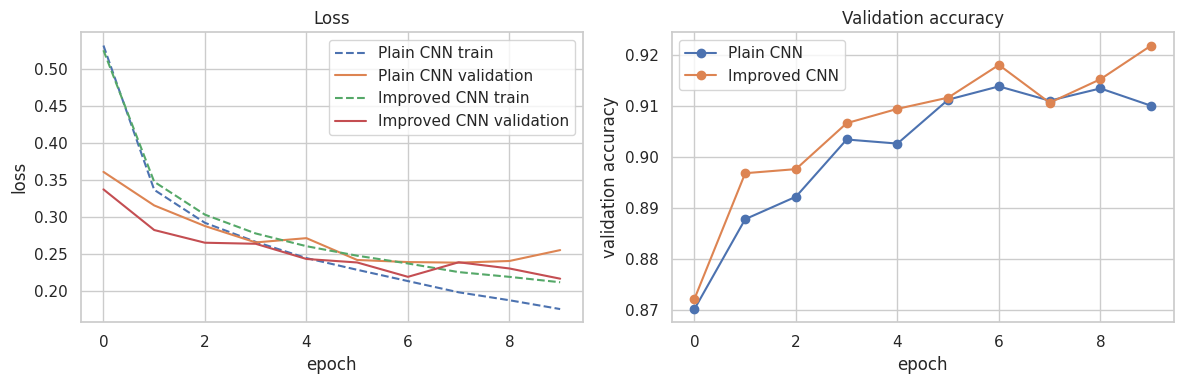

,parameters,best epoch,val loss,val acc
Plain CNN,105866.0,8.0,0.2378,0.9110
Improved CNN,98666.0,10.0,0.2161,0.9218


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [('Plain CNN', h_plain), ('Improved CNN', h_imp)]:
    ax[0].plot(h['loss'], '--', label=f'{name} train'); ax[0].plot(h['val_loss'], label=f'{name} validation'); ax[1].plot(h['val_acc'], 'o-', label=name)
ax[0].set(xlabel='epoch', ylabel='loss', title='Loss'); ax[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy'); ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()
v_plain, v_imp = evaluate(plain, val_dl), evaluate(model, val_dl)
pd.DataFrame({'Plain CNN': {'parameters': n_params(plain), 'best epoch': h_plain['best_epoch'], 'val loss': v_plain[0], 'val acc': v_plain[1]},
              'Improved CNN': {'parameters': n_params(model), 'best epoch': h_imp['best_epoch'], 'val loss': v_imp[0], 'val acc': v_imp[1]}}).T.round(4)

## 5. Final evaluation on the test set (once)
Decision made on validation data: we keep the **improved CNN**. The test set (10,000 images) has not been used for any choice so far. We score it **once**.

In [ ]:
test_loss, test_acc = evaluate(model, test_dl)
print(f'TEST accuracy: {test_acc:.4f}   TEST loss: {test_loss:.4f}   (validation accuracy was {v_imp[1]:.4f})')

TEST accuracy: 0.9144   TEST loss: 0.2324   (validation accuracy was 0.9218)


The test accuracy should be close to the validation accuracy. With 10,000 test images, one image is 0.0001 accuracy, so the test number is much more reliable than a tiny validation set.

## 6. Confusion matrix and per-class results

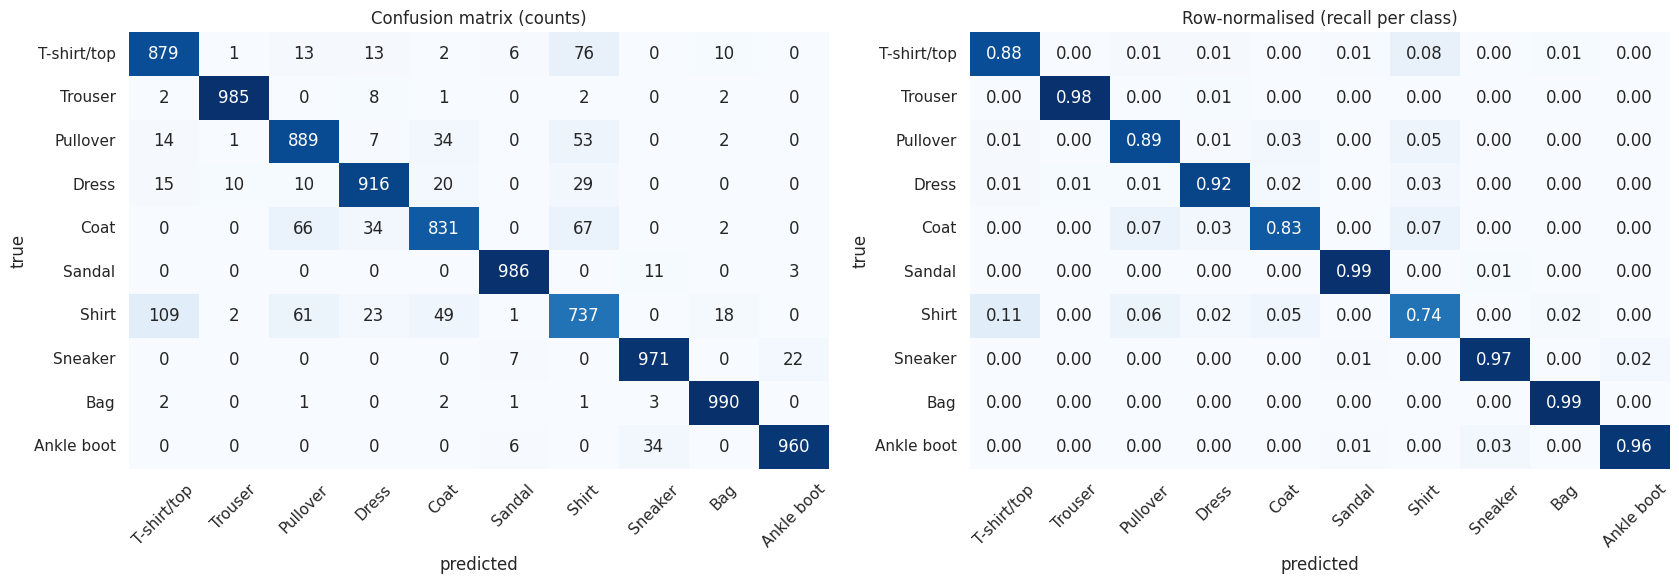

              precision    recall  f1-score   support

 T-shirt/top      0.861     0.879     0.870      1000
     Trouser      0.986     0.985     0.985      1000
    Pullover      0.855     0.889     0.872      1000
       Dress      0.915     0.916     0.916      1000
        Coat      0.885     0.831     0.857      1000
      Sandal      0.979     0.986     0.983      1000
       Shirt      0.764     0.737     0.750      1000
     Sneaker      0.953     0.971     0.962      1000
         Bag      0.967     0.990     0.978      1000
  Ankle boot      0.975     0.960     0.967      1000

    accuracy                          0.914     10000
   macro avg      0.914     0.914     0.914     10000
weighted avg      0.914     0.914     0.914     10000

Most common confusions (true -> predicted):
   109  Shirt -> T-shirt/top
    76  T-shirt/top -> Shirt
    67  Coat -> Shirt
    66  Coat -> Pullover
    61  Shirt -> Pullover


In [ ]:
model.eval(); preds, labels, probs = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        out = model(xb.to(device)); probs.append(torch.softmax(out, 1).cpu()); preds.append(out.argmax(1).cpu()); labels.append(yb)
preds, labels, probs = torch.cat(preds).numpy(), torch.cat(labels).numpy(), torch.cat(probs).numpy()

cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax[0], cbar=False); ax[0].set(xlabel='predicted', ylabel='true', title='Confusion matrix (counts)')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax[1], cbar=False); ax[1].set(xlabel='predicted', ylabel='true', title='Row-normalised (recall per class)')
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
print(classification_report(labels, preds, target_names=classes, digits=3))

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], classes[i], classes[j]) for i in range(10) for j in range(10) if i != j], reverse=True)[:5]
print('Most common confusions (true -> predicted):')
for c, a, b in pairs: print(f'  {c:4d}  {a} -> {b}')

## 7. Look at the mistakes

856 of 10000 test images are wrong


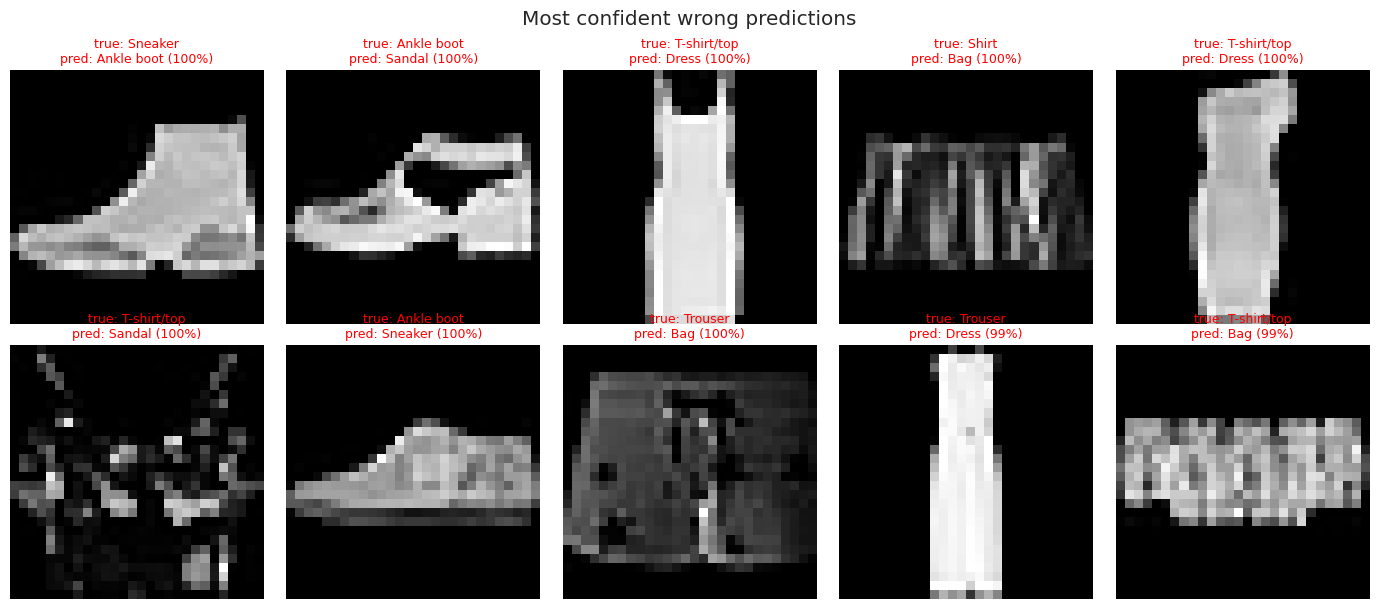

In [ ]:
wrong = np.where(preds != labels)[0]
print(f'{len(wrong)} of {len(labels)} test images are wrong')
conf = probs[wrong].max(1); worst = wrong[np.argsort(-conf)[:10]]       # the most CONFIDENT mistakes
fig, ax = plt.subplots(2, 5, figsize=(14, 6.2))
for a, i in zip(ax.ravel(), worst):
    a.imshow(test_set[i][0].squeeze() * 0.3530 + 0.2860, cmap='gray'); a.axis('off')
    a.set_title(f'true: {classes[labels[i]]}\npred: {classes[preds[i]]} ({probs[i].max():.0%})', fontsize=9, color='red')
plt.suptitle('Most confident wrong predictions'); plt.tight_layout(); plt.show()

## 8. What did the CNN learn?
**First-layer filters:** the 16 filters (3x3) learned by the first convolution, like the Sobel filter we found on Day 1.
**Feature maps:** what each filter outputs for one image, after the first and the second block.

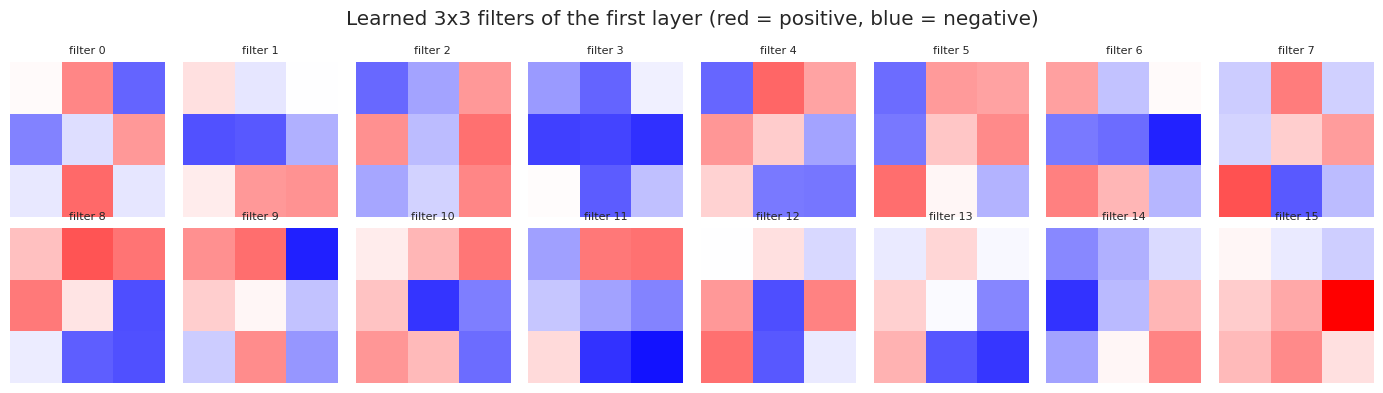

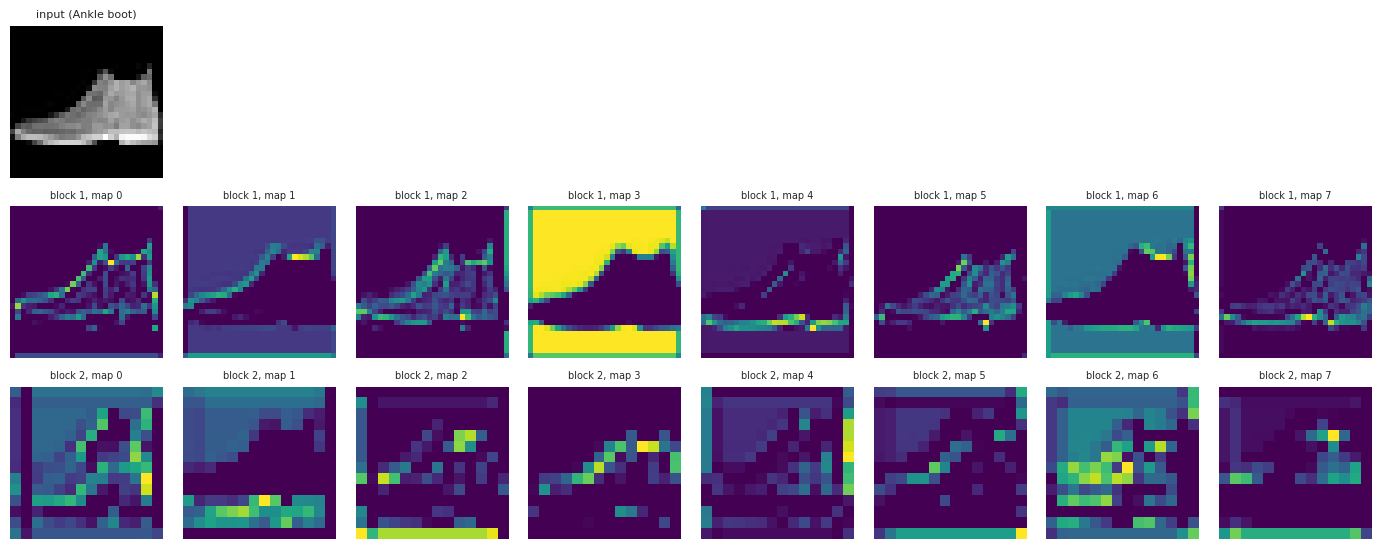

In [ ]:
W = model[0].weight.detach().cpu()                 # shape (16, 1, 3, 3)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, k in zip(ax.ravel(), range(16)):
    a.imshow(W[k, 0], cmap='bwr', vmin=-W.abs().max(), vmax=W.abs().max()); a.axis('off'); a.set_title(f'filter {k}', fontsize=8)
plt.suptitle('Learned 3x3 filters of the first layer (red = positive, blue = negative)'); plt.tight_layout(); plt.show()

img, lab = test_set[0]
model.eval(); h = img[None].to(device)
with torch.no_grad():
    f1 = model[:3](h).cpu()[0]                      # after Conv + BN + ReLU of block 1  -> (16, 28, 28)
    f2 = model[:7](h).cpu()[0]                      # after block 2 conv + BN + ReLU      -> (32, 14, 14)
fig, ax = plt.subplots(3, 8, figsize=(14, 5.6))
ax[0, 0].imshow(img.squeeze(), cmap='gray'); ax[0, 0].set_title(f'input ({classes[lab]})', fontsize=8)
for a in ax[0, 1:]: a.axis('off')
for k in range(8): ax[1, k].imshow(f1[k], cmap='viridis'); ax[1, k].set_title(f'block 1, map {k}', fontsize=7)
for k in range(8): ax[2, k].imshow(f2[k], cmap='viridis'); ax[2, k].set_title(f'block 2, map {k}', fontsize=7)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 9. Save the model

In [ ]:
torch.save(model.state_dict(), 'fashion_cnn.pt')
reloaded = improved_cnn().to(device); reloaded.load_state_dict(torch.load('fashion_cnn.pt', map_location=device))
print('Reloaded model test accuracy:', round(evaluate(reloaded, test_dl)[1], 4))

Reloaded model test accuracy: 0.9144
